<a href="https://colab.research.google.com/github/SethATU/ml-campus_data_project-colab/blob/main/miniProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machien Learning Mini Project - Seth Butler

## -Librarys-

In [266]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [267]:
import pandas as pd

These inmports are used to acess the datasheet for data analisis
- Adding google drive to project to acess the campus datasheet
- Adding the pandas library for data analisis

In [268]:
df = pd.read_csv(
    '/content/drive/MyDrive/Colab Notebooks/CampusWalkDataset_TemplateIDs.csv',
    skiprows = 4
    )

- Creating the campus walk datasheet as a DataFrame

## -Cleaning Data-

### Creating table
The code below displayed a table of the data with any Row and Columb containing NaN removed.
However if a row is has 1 cell missing data, the whole row is removed. which losses valuable data. and must be fixed.

In [269]:
# Drop columns and rows that have NaN
cleaned_df = df.dropna(how='all', axis=0)
cleaned_df = cleaned_df.dropna(how='all', axis=1) # Columns
cleaned_df = cleaned_df.dropna(how='any', axis=0) # Rows

# Set pandas options to display all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# Display the complete cleaned table
display(cleaned_df.head())

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
5,R26_002,22/09/2026,L01 MainEntrance,Sunny,17,Moderate,Low,Traffic,Human voices,Other birds,Insects,2.0,4.0,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush
10,R26_003,22/09/2026,L01 MainEntrance,Sunny,18,Moderate,Low,Traffic,Human voices,Other birds,Wind,1.0,4.0,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush
32,R26_007,22/09/2026,L04 PathFrontiHub,Sunny,17,Loud,Moderate,Traffic,Human voices,Other birds,Wind,3.0,1.0,One or two,Some,Some,Some,Neutral,Slighly uneasy,Mostly calm,No change,Wind,Ambulance
40,R26_009,22/09/2026,L01 MainEntrance,Sunny,16,Moderate,Moderate,Human voices,Traffic,Trees,Other birds,1.0,3.0,Many,Some,Many,Some,Positive wellbeing,Neutral,Mostly calm,A little more connected,Barren,People smoking
41,R26_009,22/09/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,1.0,1.0,Many,Many,Some,Many,Very positive wellbeing,Easy,Very calm,Much more connected,Fallen leaves,Bags left outside library wall


### Keep empty cells
The updated code below works by these steps.
- Removes Rows and Columns with noting in them
- Convert cells containing NaN to empty space (" ")
- Cteate a new list from old list with rows 2-23 sliced out / Because column 0 and 1 contain preinput data
- Saves rows if they have data anywhere in colums 2-23
- Updates original List to only contain the rows and colums with data (Including the " ", only if data is in the row/column)

In [270]:
# Drop columns and rows that have NaN
cleaned_df = df.dropna(how='all', axis=0)
cleaned_df = cleaned_df.dropna(how='all', axis=1)

# Fill all NaN cells with an empty space
cleaned_df = cleaned_df.fillna(value= " ")

# Get List of colum names and slice list for colums 2 to 23
target_cols = cleaned_df.columns[2:23]

# Check if all the cells in colums 2-23 are " "
# If it is not all " " then save it to rows_to_keep
rows_to_keep = ~(cleaned_df[target_cols] == " ").all(axis=1)

# Update the Cleaned DataFrame with only rows and colums that have data in them
cleaned_df = cleaned_df[rows_to_keep]

# Set pandas options to display all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns',None)
pd.set_option('display.width', None)

# Display the table
display(cleaned_df.head())

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,22/09/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,
1,R26_001,22/09/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,,Some,,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,,Some,,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,


### Remove unneeded data
The code bellow addeds on to cleaning data by doing the following.
- Removes the Columns (*recorder_id, date, other_notes , most_notable_nature_element*) as they are not needed for the investigation and will cause issues
- Once the NaN cells have been removed the left over empty space in the rows and colums needed is updated to a vlue of "0", "0" will represent data to ignore in the later steps of corelation


In [271]:
cleaned_df = df.dropna(how='all', axis=0)
cleaned_df = cleaned_df.dropna(how='all', axis=1)
cleaned_df = cleaned_df.fillna(value=" ")

# Dropping unneeded columns
cleaned_df = cleaned_df.drop(columns=['recorder_id', 'date', 'other_notes', 'most_notable_nature_element'], errors='ignore')

target_cols = cleaned_df.columns[2:23]
rows_to_keep = ~(cleaned_df[target_cols] == " ").all(axis=1)

# Change empty spaces to 0
cleaned_df = cleaned_df.replace(" ", 0)

cleaned_df = cleaned_df[rows_to_keep]

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

display(cleaned_df.head())

/tmp/ipykernel_945/3302649959.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cleaned_df = cleaned_df.replace(" ", 0)


,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating
0,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected
1,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,0,Some,0,Positive wellbeing,Neutral,Neutral,A little more connected
2,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,0,Many,Some,Positive wellbeing,Easy,Mostly calm,No change
3,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,0,Some,Positive wellbeing,Neutral,Neutral,Much more connected
4,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,0,Some,0,Positive wellbeing,Easy,Mostly calm,Less connected


## -Encoding-

### String input data
Bellow the topics that have their data as Strings are converted to ints for data analisis.
- The columns with string values are singled out and encoded to a value starting at "1" and going up until all options are a diffrent type of value
- The values that are already "0" are ignored as to not be icluded in the comparison

In [272]:
for col in cleaned_df.columns:
  # column headers to convert (removed 'weather' so it can be manually mapped later)
  if col in ['location',
              'weather',
              'sound level',
              'foot_traffic',
              'primary_sound_type_urban',
              'other_sound_type_urban',
              'primary_sound_type_nature',
              'other_sound_type_nature',
              'trees_presence',
              'native_or_wild_plant_presence',
              'ornnamental_or_planted_plant_presence',
              'moss_or_lichen_presence',
              'wellbeing_rating',
              'ease_rating',
              'stress_rating',
              'nature_connection_experience_rating'
              ]:

      # Keep track of where the 0s are
      is_zero = (cleaned_df[col] == 0) | (cleaned_df[col] == "0")

      # Convert to category codes + 1 for non-zero values
      cleaned_df[col] = cleaned_df[col].astype(str).astype('category')
      encoded_codes = cleaned_df[col].cat.codes + 1

      # Keep original 0s as 0
      cleaned_df[col] = encoded_codes.where(~is_zero, 0)

display(cleaned_df.head())

,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating
0,1,2,16,3,2,2,6,6,6,0.0,1.0,2,3,3,3,3,2,3,2
1,2,3,16,2,2,5,3,6,6,0.0,2.0,2,0,3,0,3,2,2,1
2,6,2,16,3,2,1,6,6,4,10.0,20.0,2,0,2,3,3,1,1,4
3,8,2,16,2,2,2,3,6,4,0.0,2.0,3,3,0,3,3,2,2,3
4,6,3,16,2,2,5,4,6,6,0.0,0.0,3,0,3,0,3,1,1,2


### Int input data
The bellow code takes the remaining 3 colums (*temperature_c, insects_count, birds_count*) and converts them all to Int64 if they where not that already and additionally the values in *temperature_c* remove the 'C' as to not have unessisary double values of the same int.

In [273]:
# Clean temperature bird_count and insect_count columns
# convert to string
cleaned_df['temperature_c'] = cleaned_df['temperature_c'].astype(str)

# Strip 'C' or 'c' from if included in data
cleaned_df['temperature_c'] = cleaned_df['temperature_c'].str.replace('C', '', case=False)
cleaned_df['temperature_c'] = cleaned_df['temperature_c'].str.replace('c', '', case=False)

# Connvert to numerical data
cleaned_df['temperature_c'] = pd.to_numeric(cleaned_df['temperature_c'], errors="coerce")
cleaned_df['insects_count'] = pd.to_numeric(cleaned_df['insects_count'], errors="coerce")
cleaned_df['birds_count'] = pd.to_numeric(cleaned_df['birds_count'], errors="coerce")

# Round to nearest int and convert to int64
cleaned_df['temperature_c'] = cleaned_df['temperature_c'].round().astype('Int64')
cleaned_df['insects_count'] = cleaned_df['insects_count'].round().astype('Int64')
cleaned_df['birds_count'] = cleaned_df['birds_count'].round().astype('Int64')

# Verify the cleaned values
print(" --- Cleaned 'temperature_c' value counts --- ")
print(cleaned_df['temperature_c'].value_counts(dropna=False))
print("\n")
print(" --- Cleaned 'insects_count' value counts --- ")
print(cleaned_df['insects_count'].value_counts(dropna=False))
print("\n")
print(" --- Cleaned 'birds_count' value counts --- ")
print(cleaned_df['birds_count'].value_counts(dropna=False))

display(cleaned_df.head())

 --- Cleaned 'temperature_c' value counts --- 
temperature_c
17    72
16    36
18    12
19     6
15     4
10     3
13     1
14     1
Name: count, dtype: Int64


 --- Cleaned 'insects_count' value counts --- 
insects_count
0     49
1     30
2     15
3     15
6      5
5      5
4      4
7      3
10     3
20     3
31     1
26     1
25     1
Name: count, dtype: Int64


 --- Cleaned 'birds_count' value counts --- 
birds_count
0     46
2     24
1     24
3     23
4      7
5      3
6      3
12     2
20     1
10     1
13     1
Name: count, dtype: Int64


,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating
0,1,2,16,3,2,2,6,6,6,0,1,2,3,3,3,3,2,3,2
1,2,3,16,2,2,5,3,6,6,0,2,2,0,3,0,3,2,2,1
2,6,2,16,3,2,1,6,6,4,10,20,2,0,2,3,3,1,1,4
3,8,2,16,2,2,2,3,6,4,0,2,3,3,0,3,3,2,2,3
4,6,3,16,2,2,5,4,6,6,0,0,3,0,3,0,3,1,1,2


In [274]:
# Flip the stress_rating scale so that 5 becomes 1, and 1 becomes 5
# This ensures that lower stress (which is better) gets a higher score
cleaned_df['wellbeing_rating'] = 6 - cleaned_df['wellbeing_rating']

## -Scaling-

### Scaling data
The data after cleaning and encoding is scaled, thsi is done because if you have diffrent values that variy in great amounts then the results may be skewed.
The use of scaling brings then to mostly the same values but it still varys enouch to show correlation and diffrences across the data

In [275]:
#import scaling library
from sklearn.preprocessing import scale

#scales the dataframe
scaled_df = scale(cleaned_df)
scaled_df = pd.DataFrame(scaled_df, columns=cleaned_df.columns)

display(scaled_df.head())

,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating
0,-1.497887,-0.951645,-0.480406,1.022948,-0.200805,-1.155204,1.439139,0.729338,0.437581,-0.537246,-0.357106,-0.240256,0.682288,0.896589,0.822108,-0.115518,-0.144484,0.766016,-0.377479
1,-1.058290,0.320356,-0.480406,-0.446180,-0.200805,0.810584,-0.649934,0.729338,0.437581,-0.537246,0.002665,-0.240256,-2.729153,0.896589,-1.556134,-0.115518,-0.144484,-0.067953,-1.212884
2,0.700099,-0.951645,-0.480406,1.022948,-0.200805,-1.810466,1.439139,0.729338,-0.709477,1.428288,6.478545,-0.240256,-2.729153,0.095003,0.822108,-0.115518,-0.841101,-0.901922,1.293331
3,1.579294,-0.951645,-0.480406,-0.446180,-0.200805,-1.155204,-0.649934,0.729338,-0.709477,-0.537246,0.002665,1.466828,0.682288,-1.508169,0.822108,-0.115518,-0.144484,-0.067953,0.457926
4,0.700099,0.320356,-0.480406,-0.446180,-0.200805,0.810584,0.046424,0.729338,0.437581,-0.537246,-0.716877,1.466828,-2.729153,0.896589,-1.556134,-0.115518,-0.841101,-0.901922,-0.377479


## -Corrilation-


### Correlation Matrix Heatmap
We use a correlation heatmap to visually identify which features have strong positive or negative linear relationships with one another (especially looking at the rating columns like wellbeing_rating, stress_rating, and environmental factors like trees_presence or sound level).

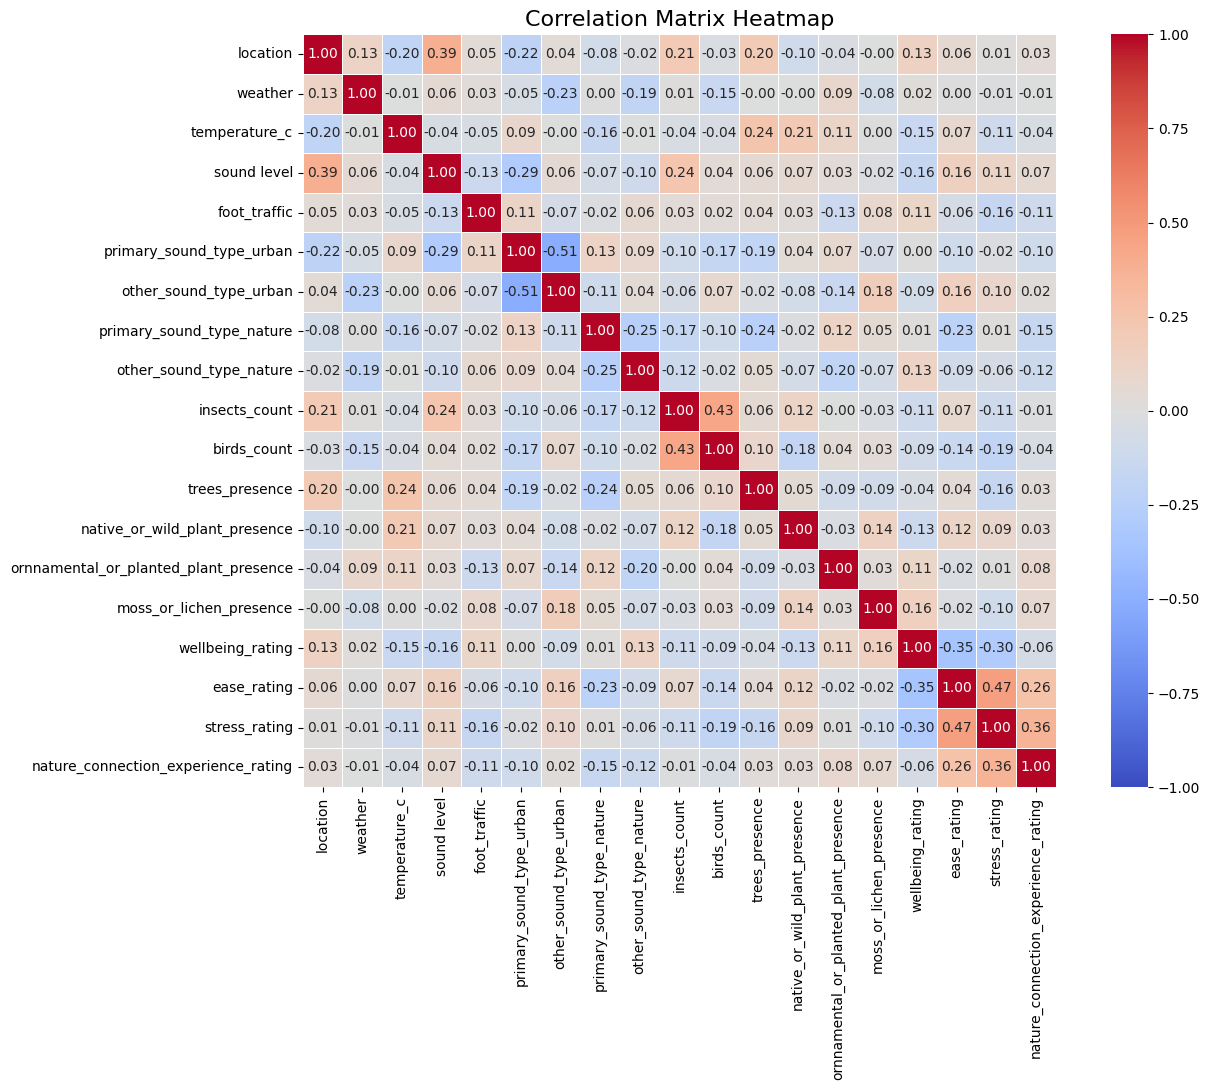

In [276]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate Pearson correlation matrix on our scaled data
corr_matrix = scaled_df.corr()

# Set up the matplotlib figure size
plt.figure(figsize=(14, 11))

# Generate a heatmap
sns.heatmap(
    corr_matrix,
    annot=True,            # Annotate cells with the numeric value
    fmt=".2f",             # Round numbers to 2 decimal places
    cmap='coolwarm',       # A diverging color scheme (red for positive, blue for negative)
    vmin=-1,               # Anchor the color map at -1
    vmax=1,                # Anchor the color map at 1
    square=True,           # Force square cells
    linewidths=0.5         # White dividers between cells
)

plt.title("Correlation Matrix Heatmap", fontsize=16)
plt.tight_layout()
plt.show()

### Scatter plot comparison

This scatter plot is used to compare the average temp per locations, as seen bellow location 9 has a big deviation from the other location.
Location 9 has a very low water raiting which is probably the cause of teh tempratuer rating being so low aswell

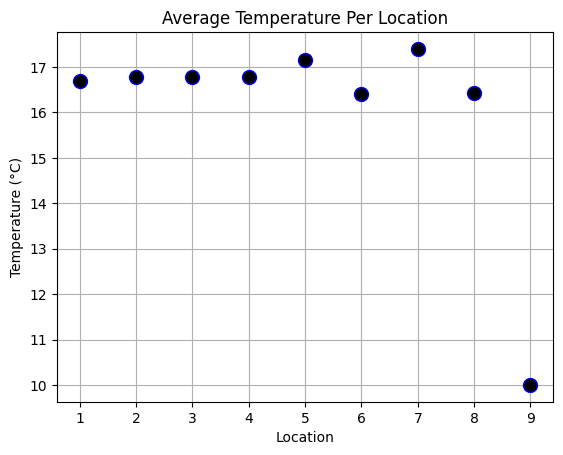

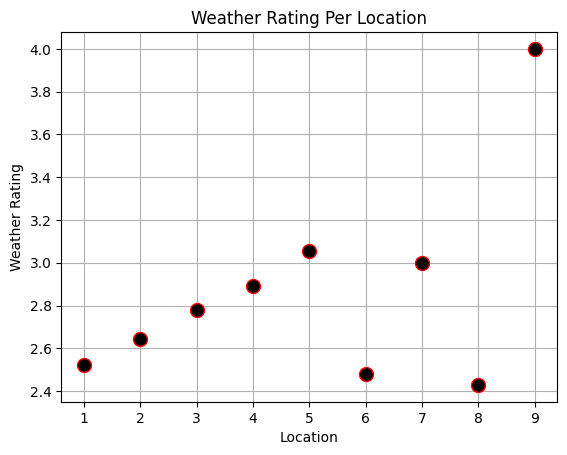

In [277]:
# Group by 'location' and calculate the average temperature for each location
avg_temp_per_loc = cleaned_df.groupby('location')['temperature_c'].mean()
weather_rating = cleaned_df.groupby('location')['weather'].mean()

# Create the scatter plot
plt.scatter(avg_temp_per_loc.index, avg_temp_per_loc.values, color='black', s=100, edgecolor='blue', zorder=2)
plt.xlabel("Location")
plt.ylabel("Temperature (°C)")
plt.title("Average Temperature Per Location")
plt.grid(True, linestyle='-', alpha=1)
plt.show()

plt.scatter(weather_rating.index, weather_rating.values, color='black', s=100, edgecolor='red', zorder=2)
plt.xlabel("Location")
plt.ylabel("Weather Rating")
plt.title("Weather Rating Per Location")
plt.grid(True, linestyle='-', alpha=1)
plt.show()

### Correlation Analysis
creating a matrix of location, weather, and temperature_c to see how strongly these specific variables correlate with one another and visualize their relationship.

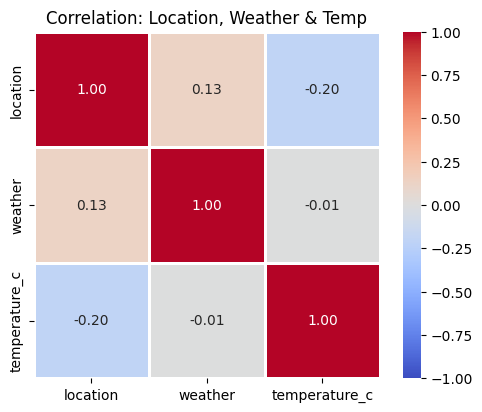

In [278]:
# Subset the data
subset_df = cleaned_df[['location', 'weather', 'temperature_c']].astype(float)

# Calculate correlation
subset_corr = subset_df.corr()

# Visualize with a small heatmap
plt.figure(figsize=(6, 4.5))
sns.heatmap(subset_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", square=True, linewidths=1)
plt.title('Correlation: Location, Weather & Temp')
plt.show()

## -Clusters-

### Generate the clusters
I will be making diffrent clusters depening on how a general walk throuch each location would be and comparing them in 3 categorys (Warm/Quiet), (Cold/Less Comfortable), (Active/Crowded), each cluster will be compared to the stress and welbing ratings



In [279]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# Fit K-Means using (K=3)
kmeans_final = KMeans(n_clusters=3, init='k-means++', max_iter=300, n_init=10, random_state=42)

# Generate cluster labels using the scaled dataframe and assign them to cleaned_df
cleaned_df['cluster_label'] = kmeans_final.fit_predict(scaled_df)

# how many data points landed in each clusters
print("--- Data Points Per Cluster ---")
print(cleaned_df['cluster_label'].value_counts())

# Calculate averages of each cluster
cluster_profile = cleaned_df.groupby('cluster_label')[[
    'wellbeing_rating',
    'stress_rating',
    'ease_rating',
    'temperature_c',
    'sound level',
    'foot_traffic',
    'trees_presence'
]].mean()

print("\n--- Cluster Profiles---")
display(cluster_profile)

--- Data Points Per Cluster ---
cluster_label
1    74
0    41
2    20
Name: count, dtype: int64

--- Cluster Profiles---


,wellbeing_rating,stress_rating,ease_rating,temperature_c,sound level,foot_traffic,trees_presence
cluster_label,,,,,,,
0,3.414634,1.707317,2.000000,16.756098,2.780488,2.097561,2.560976
1,3.364865,1.837838,1.621622,16.486486,1.986486,2.162162,1.932432
2,1.600000,3.750000,4.800000,17.0,2.500000,1.950000,2.050000


### Naming clusters
bellow the 3 clusters are given a name for a better understanding in the plot

In [280]:
# Descriptive cluster names
cluster_names_map = {
    0: '(Warm/Quiet)',
    1: '(Active/Crowded)',
    2: '(Cold/Less Comfortable)'
}

# Map the labels to a new column
cleaned_df['cluster_name'] = cleaned_df['cluster_label'].map(cluster_names_map)

# verify the change to cluster name
print("--- Data Points Per Named Cluster ---")
print(cleaned_df['cluster_name'].value_counts())

display(cleaned_df[['cluster_label', 'cluster_name', 'wellbeing_rating', 'stress_rating', 'temperature_c']].head())

--- Data Points Per Named Cluster ---
cluster_name
(Active/Crowded)           74
(Warm/Quiet)               41
(Cold/Less Comfortable)    20
Name: count, dtype: int64


,cluster_label,cluster_name,wellbeing_rating,stress_rating,temperature_c
0,1,(Active/Crowded),3,3,16
1,1,(Active/Crowded),3,2,16
2,0,(Warm/Quiet),3,1,16
3,0,(Warm/Quiet),3,2,16
4,1,(Active/Crowded),3,1,16


### Ploting the clusters
In the cluster plot you can see that
- Hight stress and low welbeing are asosiated with acold and less comfortable location
- Low stress and High welbeaing are assosiated with a warm and quiet area
- The middle ground is assosiated with active and crowded areas mostly  

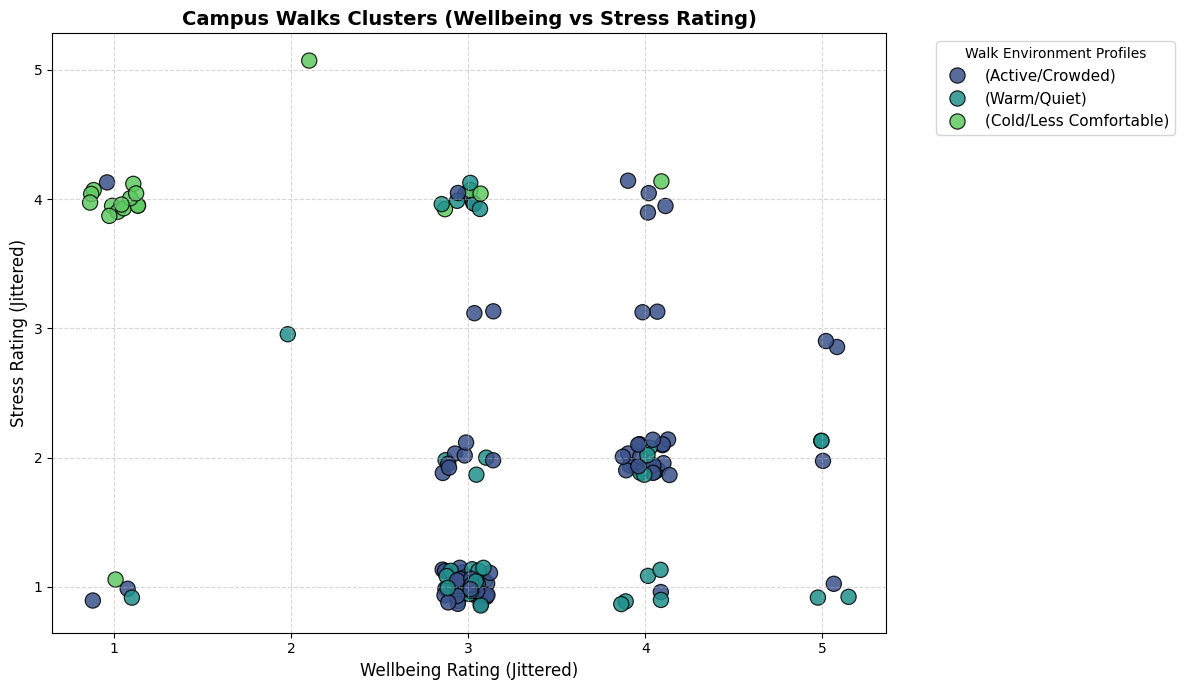

In [281]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy for plotting with jitter so point density is visible
plot_df_named = cleaned_df.copy()

# Add a tiny bit of random noise (jitter) to the discrete ratings
noise_x = np.random.uniform(-0.15, 0.15, size=len(plot_df_named))
noise_y = np.random.uniform(-0.15, 0.15, size=len(plot_df_named))

plot_df_named['wellbeing_jittered'] = plot_df_named['wellbeing_rating'] + noise_x
plot_df_named['stress_jittered'] = plot_df_named['stress_rating'] + noise_y

# Re-plot with named categories in the legend
plt.figure(figsize=(12, 7))
sns.scatterplot(
    x='wellbeing_jittered',
    y='stress_jittered',
    hue='cluster_name',
    palette='viridis',
    data=plot_df_named,
    s=120,
    alpha=0.85,
    edgecolor='black'
)

plt.title('Campus Walks Clusters (Wellbeing vs Stress Rating)', fontsize=14, fontweight='bold')
plt.xlabel('Wellbeing Rating (Jittered)', fontsize=12)
plt.ylabel('Stress Rating (Jittered)', fontsize=12)
plt.legend(title='Walk Environment Profiles', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()